
<style>
h1 {text-align: center; font-family: "Times New Roman"; }
h2 {text-align: center; font-family: "Times New Roman";}
p {text-align: left; font-family: "Times New Roman";}
</style>
<h1><b><u>Human Activity Recognition</u></b></h1> 
<h2>Decision Trees on the UCI-HAR Dataset</h2>

## 1. Waveform of each Activity

<style>p {text-align: left; font-family: "Times New Roman";}</style>

<p>Plotting the waveform for the data from each activity class, to see the differences/similarities between the activities and whether a model will be able to classify the activities based on the data.</p>

In [1]:
## Importing the libraries
import numpy as np
import os
import pandas as pd
from MakeDataset import X_train, X_test, y_train, y_test,X_val,y_val
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score
import pickle
import plotly.express as px
import tsfel
from sklearn import tree

In [2]:
## Combining the train and Validation parts of the dataset
X_combined = np.concatenate((X_train,X_test,X_val),axis=0)
y_combined = np.concatenate((y_train,y_test,y_val),axis=0)
X_combined.shape,y_combined.shape

((180, 500, 3), (180,))

In [3]:
def plot_3d(X,activity,ax):
    # Function for plotting the 3D scatter plot
    ax.scatter(X[:,:,0],X[:,:,1],X[:,:,2],c='blue',marker='o',s=20,label=activity)
    ax.set_xlabel('a_x')
    ax.set_ylabel('a_y')
    ax.set_zlabel('a_z')
    ax.set_title(activity)
    
X_activity = {}
activities = ["WALKING","WALKING_UPSTAIRS","WALKING_DOWNSTAIRS","SITTING","STANDING","LAYING"] # Array of various activities
classes = {"WALKING":1,"WALKING_UPSTAIRS":2,"WALKING_DOWNSTAIRS":3,"SITTING":4,"STANDING":5,"LAYING":6} # Dictionary for mapping activities to classes
for i in range(len(activities)):
    X_activity[activities[i]] = X_combined[y_combined==classes[activities[i]]]
    print(f"Activity: {activities[i]} length = {X_activity[activities[i]].shape}")
# X_activity is the dict containing the data for each activity

Activity: WALKING length = (30, 500, 3)
Activity: WALKING_UPSTAIRS length = (30, 500, 3)
Activity: WALKING_DOWNSTAIRS length = (30, 500, 3)
Activity: SITTING length = (30, 500, 3)
Activity: STANDING length = (30, 500, 3)
Activity: LAYING length = (30, 500, 3)


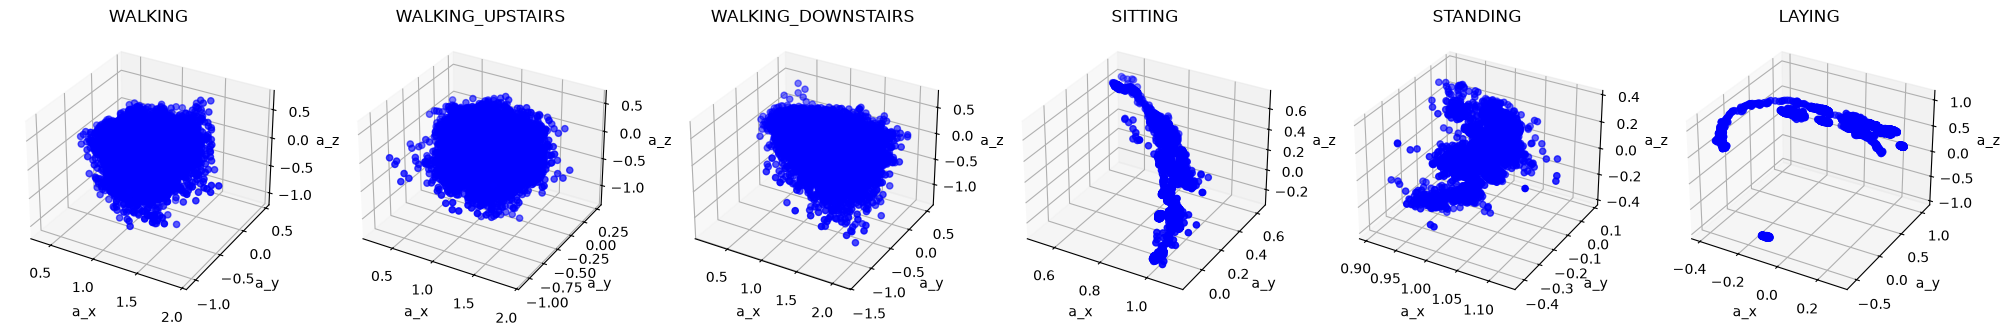

In [4]:
time = np.arange(100,600)
fig,ax = plt.subplots(1,6,figsize=(25,25),subplot_kw=dict(projection='3d'))
for i in range(len(activities)): #plotting the 3D distributions of aX,aY,aZ for each activity
    ax[i].scatter(X_activity[activities[i]][:,:,0],X_activity[activities[i]][:,:,1],X_activity[activities[i]][:,:,2],c='blue',marker='o',s=20)
    ax[i].set_xlabel('a_x')
    ax[i].set_ylabel('a_y')
    ax[i].set_zlabel('a_z')
    ax[i].set_title(activities[i])

plt.show()

<style>p {text-align: left; font-family: "Times New Roman";}</style>

<p>It can be observed from the 3D plots of these activities that the datapoints for static activities such as Sitting, Standing and Laying is confined to thin, almost linear clusters, whereas that for the other activities (dynamic ones) is very scattered.</p>

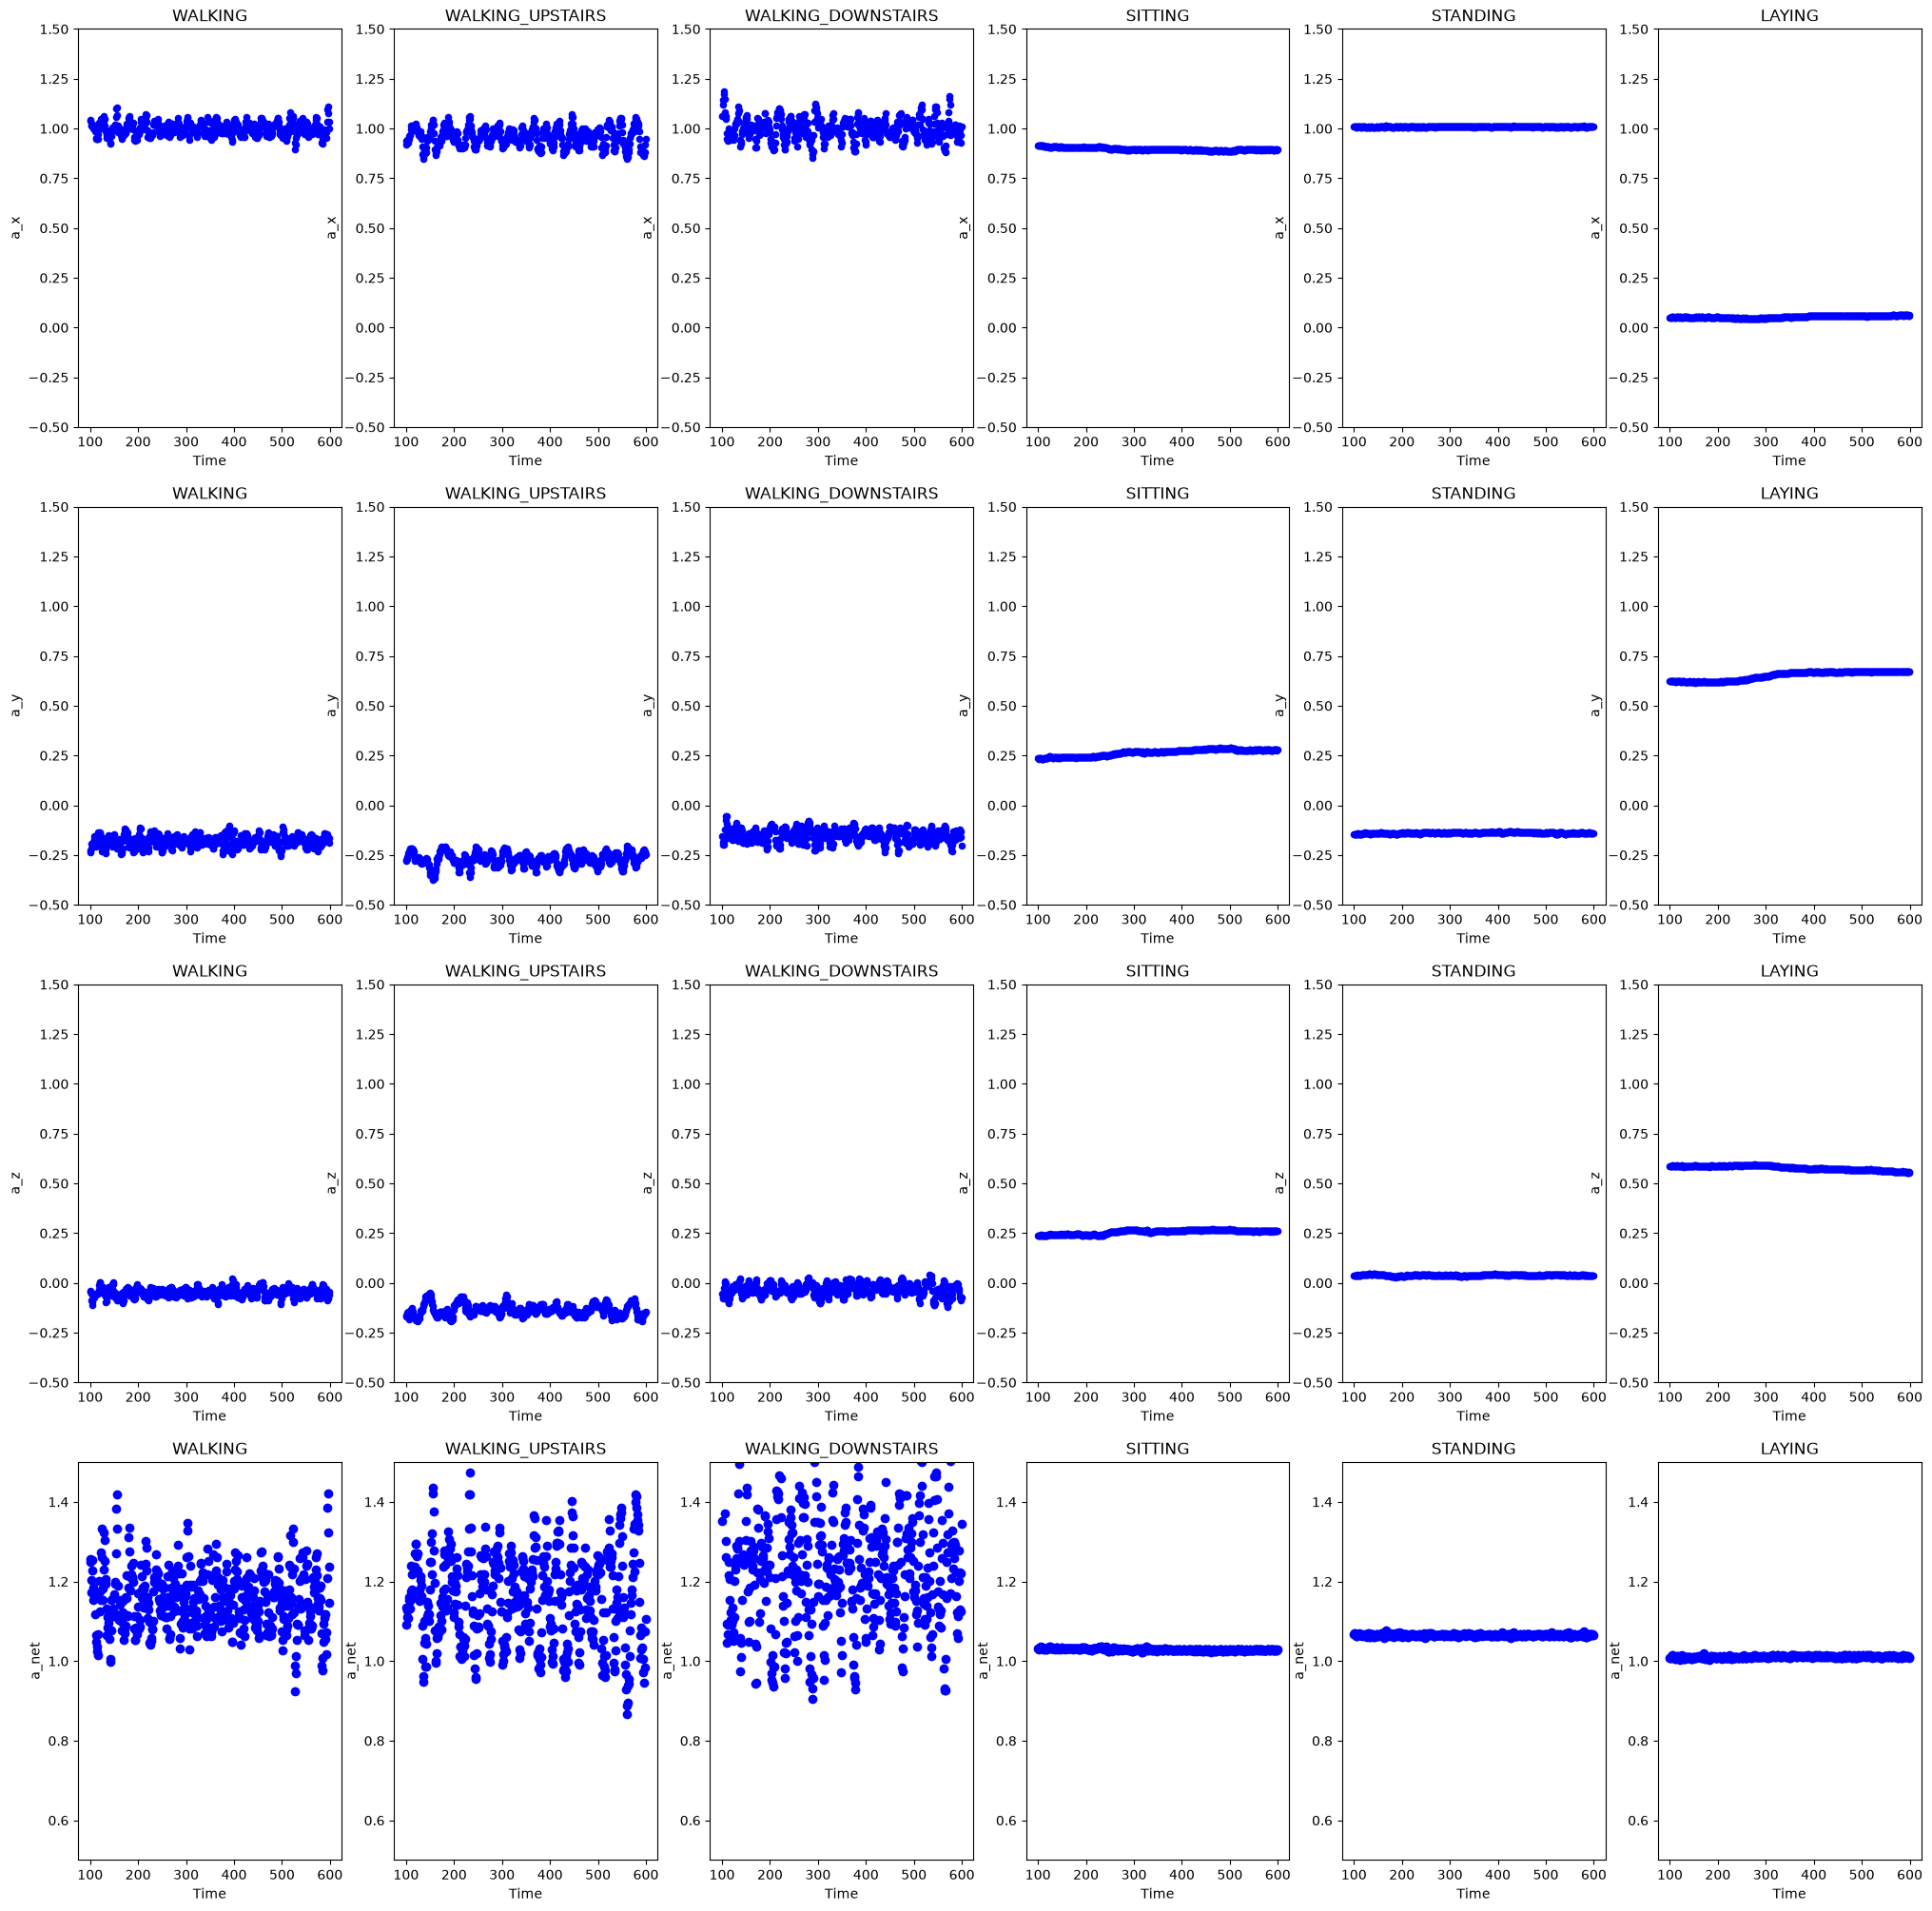

In [5]:
fig,ax = plt.subplots(4,6,figsize=(25,25))
j=0
for i in range(len(activities)): #plotting the 3D distributions of aX for each activity
    ax[j,i].scatter(time,X_activity[activities[i]][:,:,0].mean(axis=0),c='blue',marker='o',s=20)
    ax[j,i].set_xlabel('Time')
    ax[j,i].set_ylabel('a_x')
    ax[j,i].set_title(activities[i])
    ax[j,i].set_ylim(-0.5,1.5)
j=1
for i in range(len(activities)): #plotting the 3D distributions of aY for each activity
    ax[j,i].scatter(time,X_activity[activities[i]][:,:,1].mean(axis=0),c='blue',marker='o',s=20)
    ax[j,i].set_xlabel('Time')
    ax[j,i].set_ylabel('a_y')
    ax[j,i].set_title(activities[i])
    ax[j,i].set_ylim(-0.5,1.5)
j=2
for i in range(len(activities)): #plotting the 3D distributions of aZ for each activity
    ax[j,i].scatter(time,X_activity[activities[i]][:,:,2].mean(axis=0),c='blue',marker='o',s=20)
    ax[j,i].set_xlabel('Time')
    ax[j,i].set_ylabel('a_z')
    ax[j,i].set_title(activities[i])
    ax[j,i].set_ylim(-0.5,1.5)
# net acc
j=3
for i in range(len(activities)): #plotting the 3D distributions of a_net for each activity
    net_acc = np.sum(X_activity[activities[i]]**2,axis=2)
    ax[j,i].scatter(time,net_acc.mean(axis=0),c='blue',marker='o')
    ax[j,i].set_xlabel('Time')
    ax[j,i].set_ylabel('a_net')
    ax[j,i].set_title(activities[i])
    ax[j,i].set_ylim(0.5,1.5)
plt.show()

<style>
    p{font-family:"Times New Roman"}
</style>

<p> The data has been plotted for a time instance of 10s, (a total 500 instances from indices 100 to 600) at a frequency of 50Hz. It can be observed from the time series plots as given above that the distribution of <b>LAYING</b>, <b>SITTING</b>, and <b>STANDING</b> are relatively constant and "calm". However, the data of <b>WALKING</b>, <b>WALKING_DOWNWARD</b>, and <b>WALKING_UPWARD</b> are relatively more scattered and not constant. Talking in terms of statistics, it can be seen that the mean of <i>a_x</i> while laying is almost zero, contrary to the other activities. It is also very constant. The mean of a_y for <b>SITTING</b> is around 0.25 contrary to the other activities. The value of a_x, a_y, and a_z for standing is also very constant compared to that of other walking based activities. It may be more difficult to distinguish between <b>WALKING</b>, <b>WALKING_DOWNWARD</b>, and <b>WALKING_UPWARD</b> based on the initial observations, and some other time series functions may even need to be looked through for further understanding.

## 2. Static v/s Dynamic Activities

<style>
    p{font-family:"Times New Roman";}
</style>

<p>Is a machine learning model needed to differentiate between static activities (laying, sitting, standing) and dynamic activities (walking, walking_downstairs, walking_upstairs)? The linear acceleration acc<sub>x</sub><sup>2</sup>+acc<sub>y</sub><sup>2</sup>+acc<sub>z</sub><sup>2</sup> for each activity is looked at below to answer this.</p>

<style>
    p{font-family:"Times New Roman"}
</style>

<p>No. A Machine Learning model would not be needed for the differentiation between static and dynamic activities. This is because, as can be visually inspected from the graph, the static activities have an almost constant time series plot, whereas the dynamic ones have a highly varying time series plot for various instants of time. Statistically speaking, the standard deviation between different data points for the static activities is much less than that for the dynamic ones.</p>

In [6]:
a_net_train_arr = X_train[:, :, 0]**2 + X_train[:, :, 1]**2 + X_train[:, :, 2]**2 # Calculating the net acceleration for each sample in the train set
a_net_train_arr.shape

(108, 500)

In [7]:
a_net_test_arr = X_test[:, :, 0]**2 + X_test[:, :, 1]**2 + X_test[:, :, 2]**2 # Calculating the net acceleration for each sample in the test set
a_net_test_arr.shape

(36, 500)

In [8]:
a_net_val_arr = X_val[:, :, 0]**2 + X_val[:, :, 1]**2 + X_val[:, :, 2]**2 # Calculating the net acceleration for each sample in the validation set
a_net_val_arr.shape

(36, 500)

Text(0, 0.5, 'Net Acceleration')

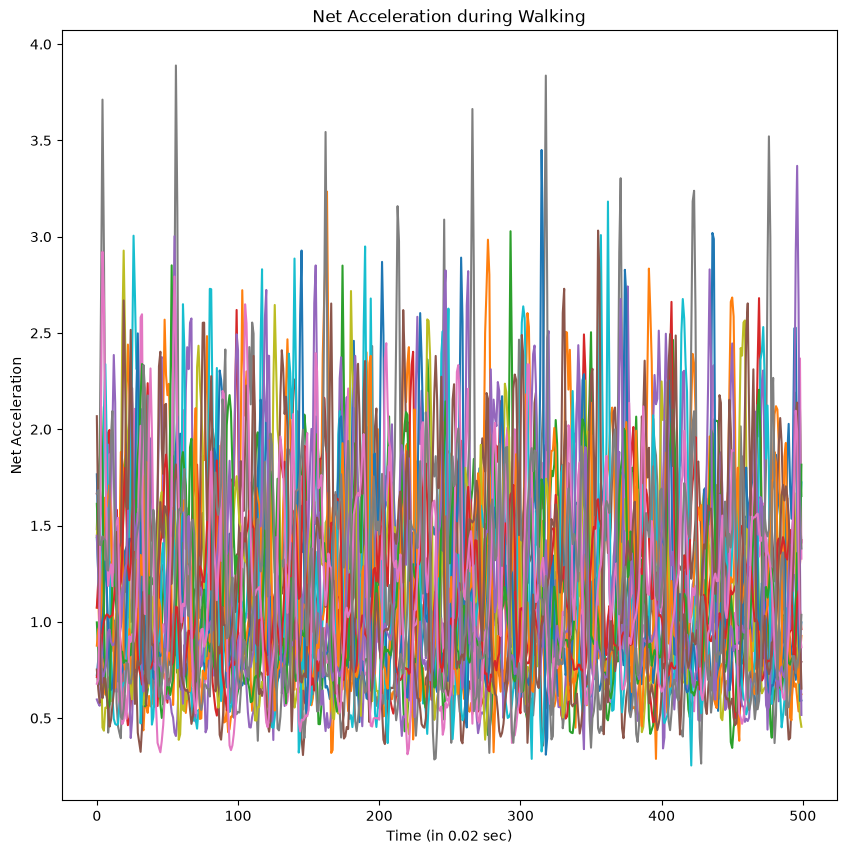

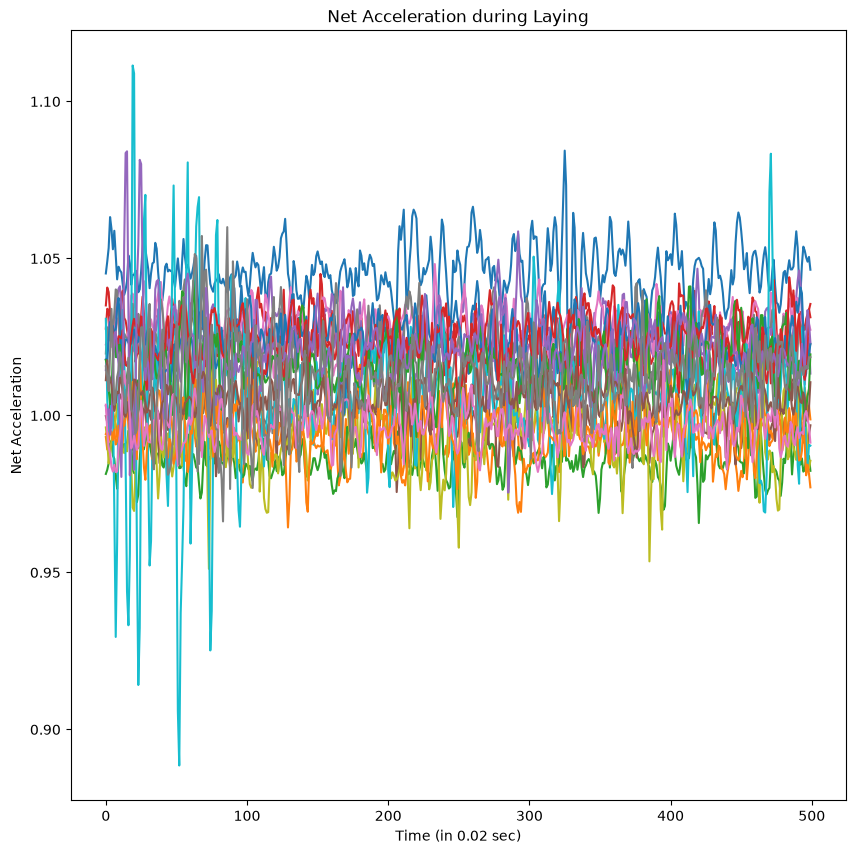

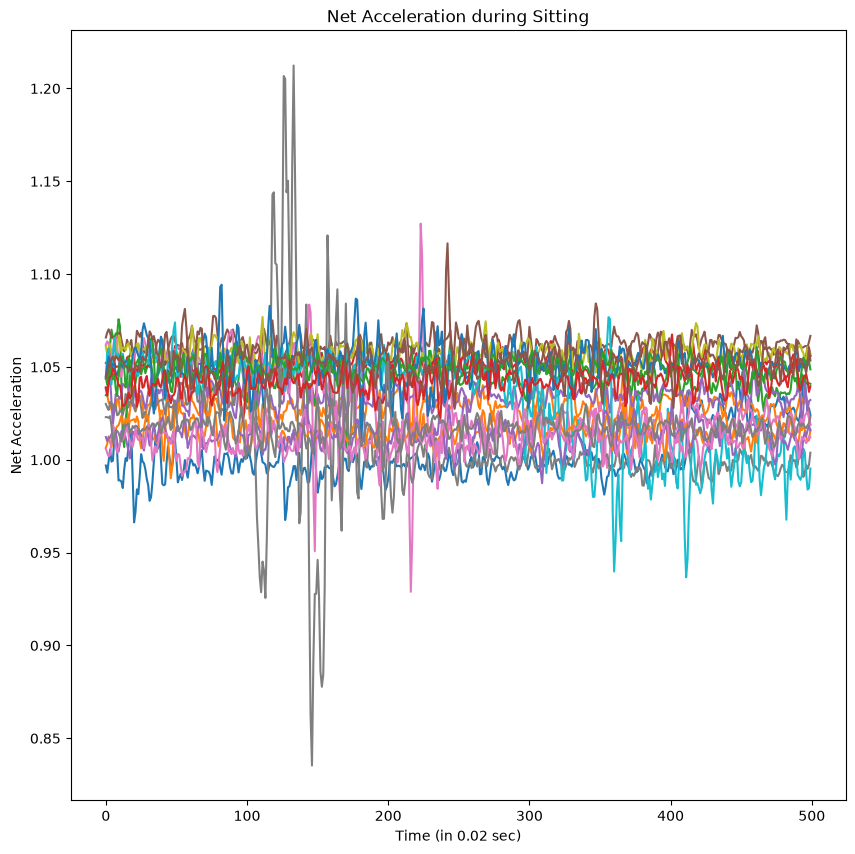

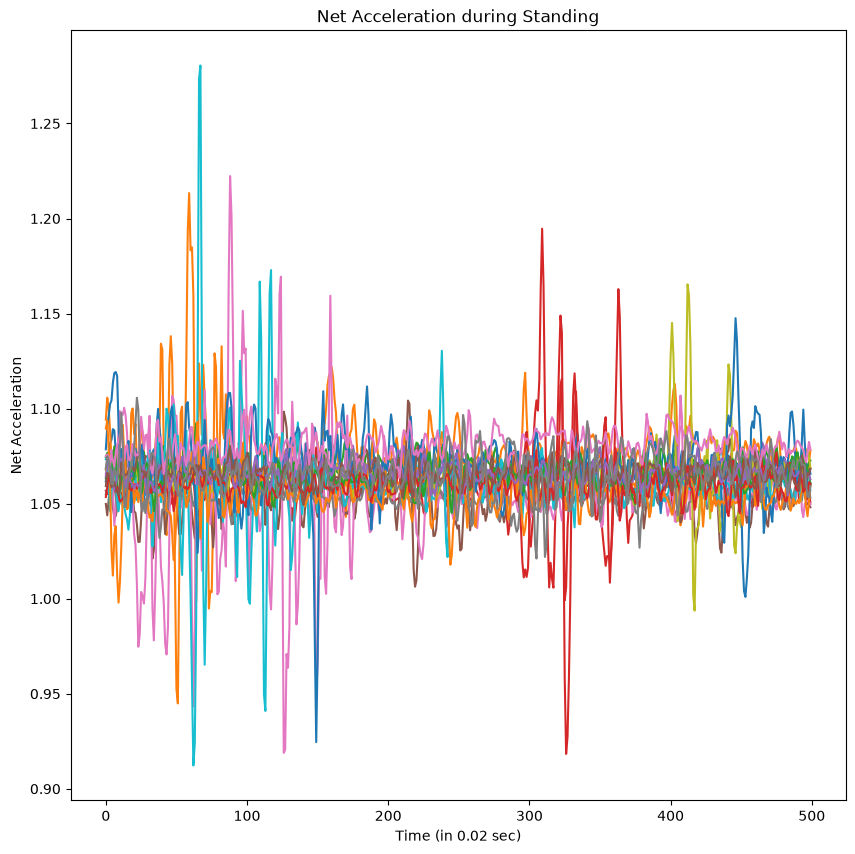

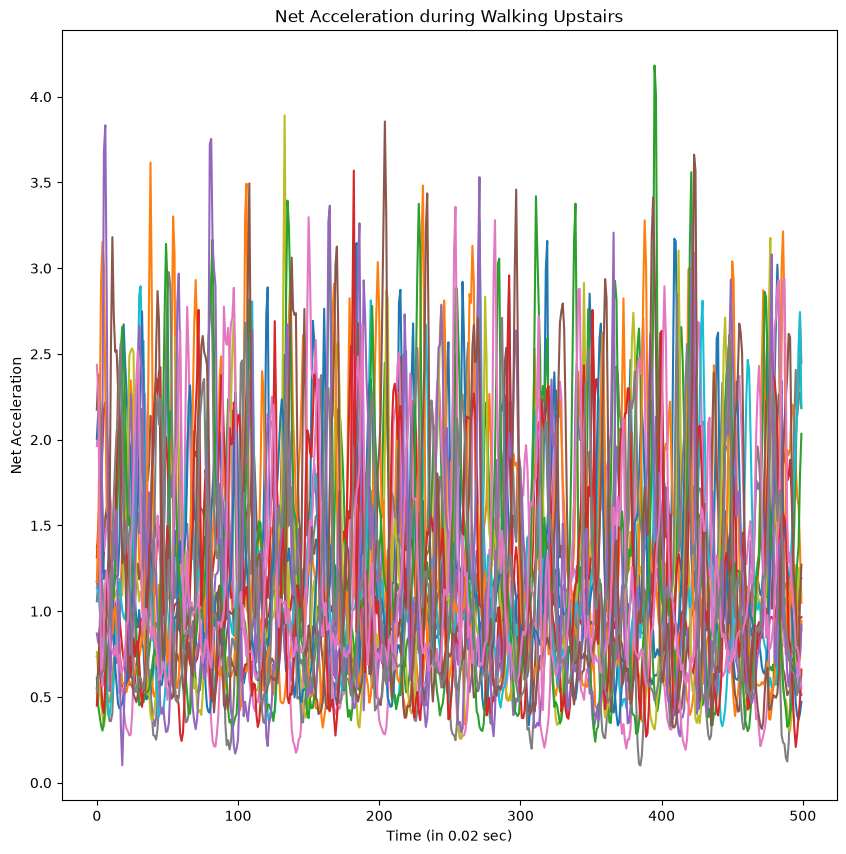

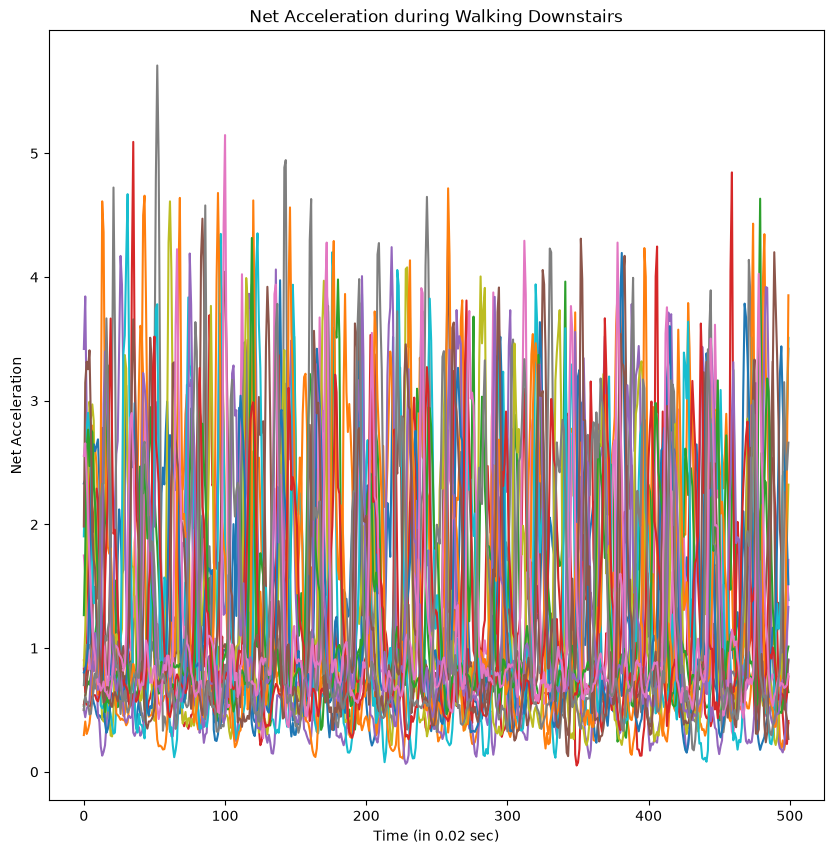

In [9]:
plt.figure(figsize=(10, 10)) # Plotting the net acceleration for each sample in the train set for walking
for i in range((a_net_train_arr.shape[0])):
    if y_train[i] == classes["WALKING"]:
        plt.plot(a_net_train_arr[i])
plt.title("Net Acceleration during Walking")
plt.xlabel("Time (in 0.02 sec)")
plt.ylabel("Net Acceleration")


plt.figure(figsize=(10, 10)) # Plotting the net acceleration for each sample in the train set for laying
for i in range((a_net_train_arr.shape[0])):
    if y_train[i] == classes["LAYING"]:
        plt.plot(a_net_train_arr[i])
plt.title("Net Acceleration during Laying")
plt.xlabel("Time (in 0.02 sec)")
plt.ylabel("Net Acceleration")


plt.figure(figsize=(10, 10)) # Plotting the net acceleration for each sample in the train set for sitting
for i in range((a_net_train_arr.shape[0])):
    if y_train[i] == classes["SITTING"]:
        plt.plot(a_net_train_arr[i])
plt.title("Net Acceleration during Sitting")
plt.xlabel("Time (in 0.02 sec)")
plt.ylabel("Net Acceleration")


plt.figure(figsize=(10, 10)) # Plotting the net acceleration for each sample in the train set for standing
for i in range((a_net_train_arr.shape[0])):
    if y_train[i] == classes["STANDING"]:
        plt.plot(a_net_train_arr[i])
plt.title("Net Acceleration during Standing")
plt.xlabel("Time (in 0.02 sec)")
plt.ylabel("Net Acceleration")


plt.figure(figsize=(10, 10)) # Plotting the net acceleration for each sample in the train set for walking upstairs
for i in range((a_net_train_arr.shape[0])):
    if y_train[i] == classes["WALKING_UPSTAIRS"]:
        plt.plot(a_net_train_arr[i])
plt.title("Net Acceleration during Walking Upstairs")
plt.xlabel("Time (in 0.02 sec)")
plt.ylabel("Net Acceleration")


plt.figure(figsize=(10, 10)) # Plotting the net acceleration for each sample in the train set for walking downstairs
for i in range((a_net_train_arr.shape[0])):
    if y_train[i] == classes["WALKING_DOWNSTAIRS"]:
        plt.plot(a_net_train_arr[i])
plt.title("Net Acceleration during Walking Downstairs")
plt.xlabel("Time (in 0.02 sec)")
plt.ylabel("Net Acceleration")

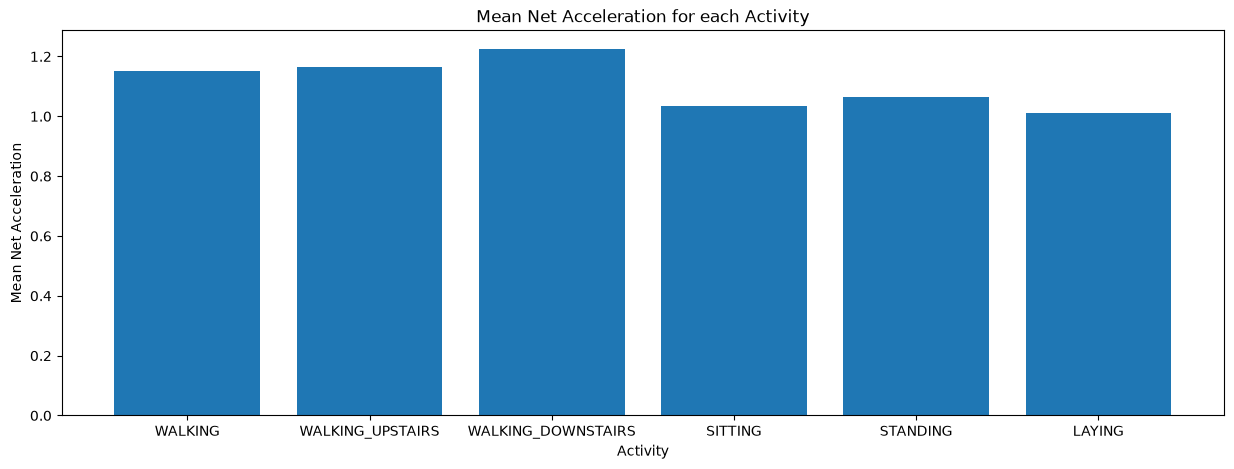

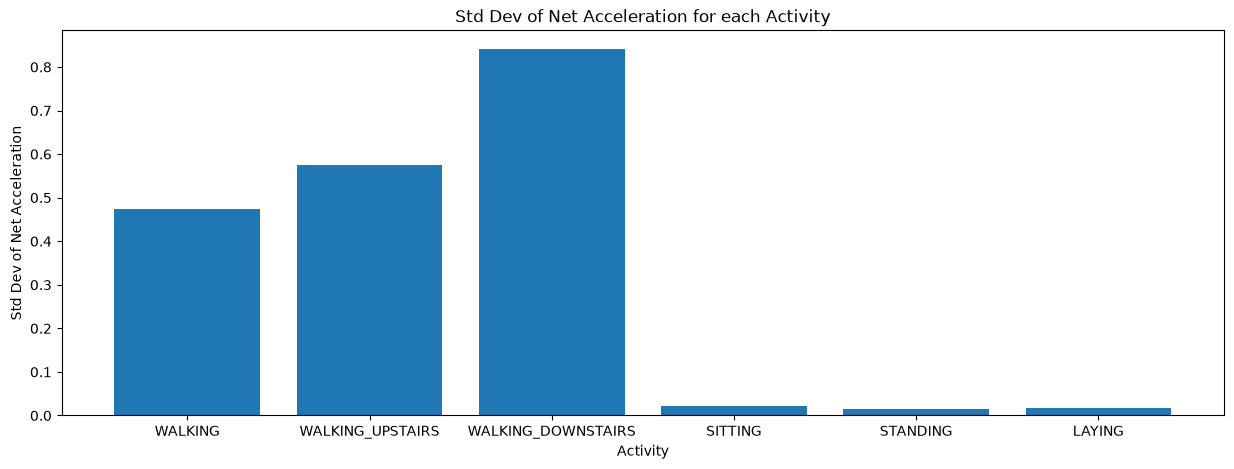

In [10]:
overall_mean_array = [] # Calculating the overall mean of the net acceleration for each activity
overall_std_dev_array = [] # Calculating the overall standard deviation of the net acceleration for each activity
for i in classes.keys():
    overall_mean_array.append(np.mean(np.mean(a_net_train_arr[y_train==classes[i]],axis=0))) # appending the mean of the net acceleration for each activity
    overall_std_dev_array.append(np.mean(np.std(a_net_train_arr[y_train==classes[i]],axis=0))) # appending the mean of the standard deviation of the net acceleration for each activity

overall_mean_array = np.array(overall_mean_array)
overall_std_dev_array = np.array(overall_std_dev_array)


# Plotting the overall mean and standard deviation of the net acceleration for each activity
plt.figure(figsize=(15, 5))
plt.bar(classes.keys(),overall_mean_array)
plt.title("Mean Net Acceleration for each Activity")
plt.xlabel("Activity")
plt.ylabel("Mean Net Acceleration")
plt.show()

plt.figure(figsize=(15, 5))
plt.bar(classes.keys(),overall_std_dev_array)
plt.title("Std Dev of Net Acceleration for each Activity")
plt.xlabel("Activity")
plt.ylabel("Std Dev of Net Acceleration")
plt.show()

## 3. Decision Tree on the Raw Data

<style>p {text-align: left; font-family: "Times New Roman";}</style>

<p>Training a Decision Tree using the trainset and reporting the accuracy and confusion matrix using the testset. The raw data used here is the linear acceleration acc<sub>x</sub><sup>2</sup>+acc<sub>y</sub><sup>2</sup>+acc<sub>z</sub><sup>2</sup> timeseries (500 samples for each participant and activity).</p>

In [11]:
acc_net_test_df = pd.DataFrame(a_net_test_arr) # Creating a dataframe for the net acceleration for each sample in the test set
acc_net_val_df = pd.DataFrame(a_net_val_arr) # Creating a dataframe for the net acceleration for each sample in the validation set
acc_net_train_df = pd.DataFrame(a_net_train_arr) # Creating a dataframe for the net acceleration for each sample in the train set

X_train_val = np.concatenate((a_net_train_arr, a_net_val_arr), axis=0) # Combining the train and validation parts of the dataset
y_train_val = np.concatenate((y_train, y_val), axis=0) # Combining the train and validation parts of the labels

dec_tree = DecisionTreeClassifier(criterion='entropy', max_depth=9, random_state=42) # Creating a decision tree classifier
dec_tree.fit(X_train_val, y_train_val) # Fitting the decision tree classifier on the train and validation parts of the dataset

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

Model accuracy on test set: 0.5277777777777778


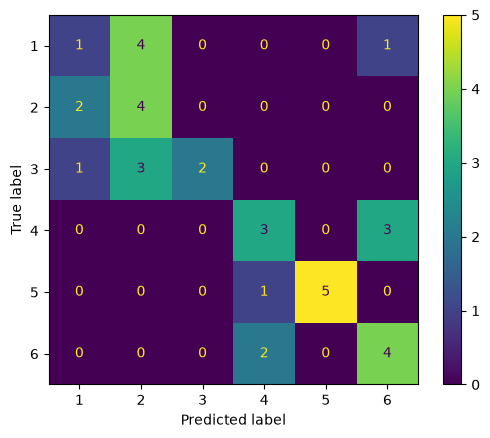

In [12]:
y_pred = dec_tree.predict(a_net_test_arr) # Predicting the labels for the test set
print(f"Model accuracy on test set: {accuracy_score(y_test, y_pred)}") # Printing the accuracy of the model on the test set
cm = confusion_matrix(y_test, y_pred) # Calculating the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dec_tree.classes_) # Creating a confusion matrix display
disp.plot() # Plotting the confusion matrix
plt.show() # Displaying the confusion matrix

In [13]:
filename = 'Final Model/raw_tree.sav' # Path for the Decision Tree trained on the raw data
pickle.dump(dec_tree, open(filename, 'wb')) # Pickling/Saving the Decision Tree trained on the raw data (it is tested later on the collected data)

## 4. Decision Trees of Varying Depths

<style>p {text-align: left; font-family: "Times New Roman";}</style>

<p>Training Decision Trees with varying depths (2-8) using the trainset and reporting the accuracy and confusion matrix using the test set, to see whether the accuracy changes when the depth is increased.</p>

<style>
    p {font-family:"Times New Roman"}
</style>
<p> The decision tree of various depths has been formed and the accuracy measures have been plotted for different heights. The main observations were that the highest accuracy obtained with this data is 52.8%. The accuracy plot against the height of the tree shows that the accuracy on smaller heights of trees is quite low, and then gradually increases, after which it attains a stable value with minor fluctuations within the window of observation </p>

Accuracy Score for max depth =  2 is 0.4444444444444444
Confusion Matrix for max depth =  2


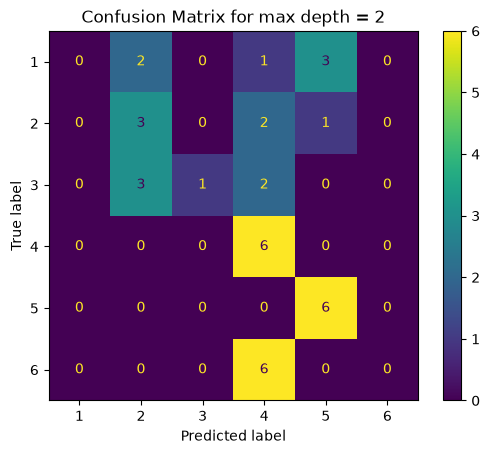

-----------------------------------------------------------
Accuracy Score for max depth =  3 is 0.5
Confusion Matrix for max depth =  3


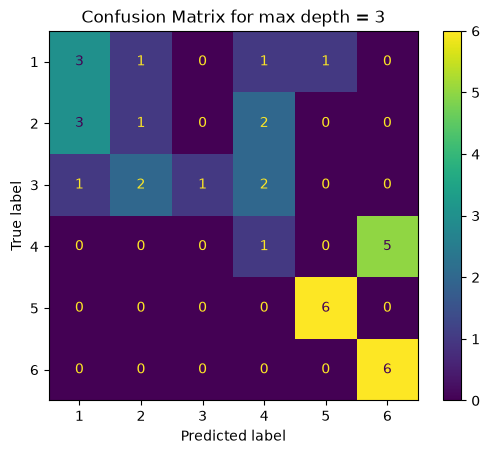

-----------------------------------------------------------
Accuracy Score for max depth =  4 is 0.5277777777777778
Confusion Matrix for max depth =  4


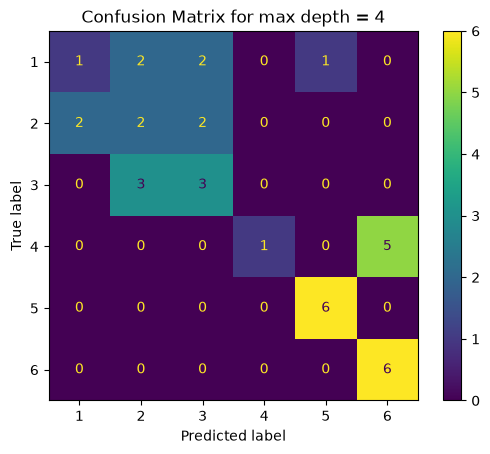

-----------------------------------------------------------
Accuracy Score for max depth =  5 is 0.5277777777777778
Confusion Matrix for max depth =  5


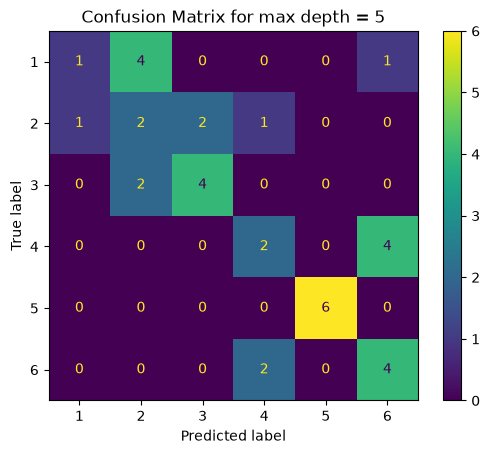

-----------------------------------------------------------
Accuracy Score for max depth =  6 is 0.5
Confusion Matrix for max depth =  6


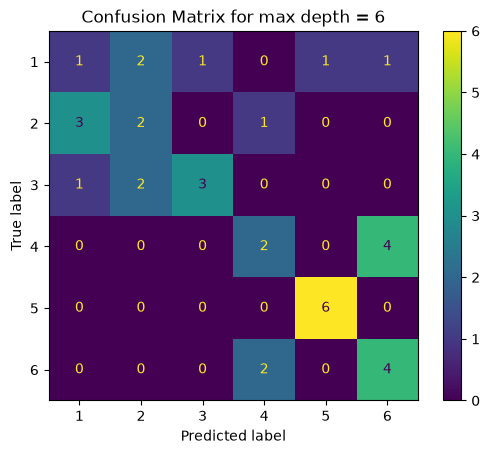

-----------------------------------------------------------
Accuracy Score for max depth =  7 is 0.5
Confusion Matrix for max depth =  7


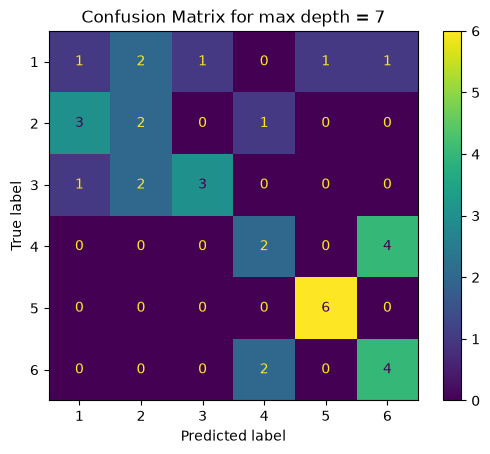

-----------------------------------------------------------
Accuracy Score for max depth =  8 is 0.5
Confusion Matrix for max depth =  8


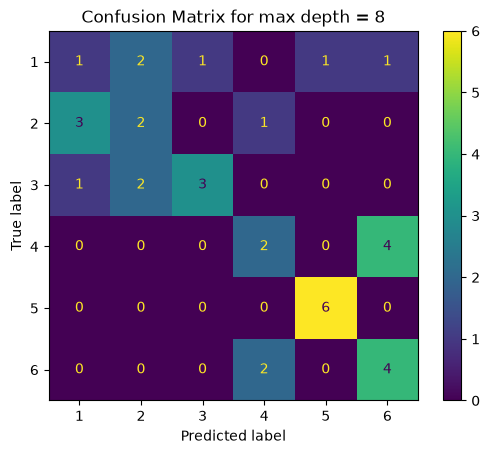

-----------------------------------------------------------


In [14]:
dict_heightVSaccuracy = {} # Creating a dictionary for storing the accuracy of the model for each max depth
for i in range(2, 9): # Looping over the max depth
    dtree = DecisionTreeClassifier(max_depth=i, random_state=42) # Creating a decision tree classifier of max depth = i
    dtree.fit(X_train_val, y_train_val) # Fitting the decision tree classifier on the train and validation parts of the dataset
    ypred = dtree.predict(a_net_test_arr) # Predicting the labels for the test set
    print("Accuracy Score for max depth = ", i, "is", accuracy_score(y_test, ypred)) # Printing the accuracy of the model on the test set
    print("Confusion Matrix for max depth = ", i) # Printing the confusion matrix
    dict_heightVSaccuracy[i] = accuracy_score(y_test, ypred) # Storing the accuracy of the model for each max depth
    cm = confusion_matrix(y_test, ypred) # Calculating the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dtree.classes_) # Creating a confusion matrix display
    disp.plot() # Plotting the confusion matrix
    plt.title("Confusion Matrix for max depth = "+str(i))
    plt.show()
    print("-----------------------------------------------------------")

Text(0.5, 1.0, 'The accuracy of the tree for various tree depths')

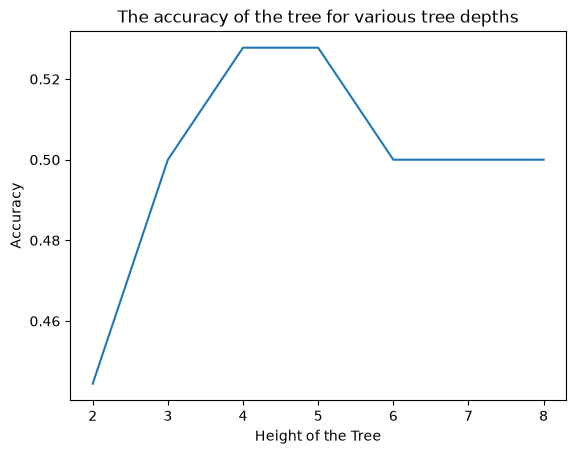

In [15]:
acc_axis = dict_heightVSaccuracy.values() # Creating an array for storing the accuracy of the model for each max depth
height_axis = dict_heightVSaccuracy.keys() # Creating an array for storing the max depth

plt.figure() 
plt.plot(height_axis, acc_axis)# Plotting the accuracy of the model for each max depth 
plt.xlabel("Height of the Tree")
plt.ylabel("Accuracy")
plt.title("The accuracy of the tree for various tree depths")

## 5. PCA on the Raw Data and on the TSFEL Features

<style>p {text-align: left; font-family: "Times New Roman";}</style>
<p>Using PCA (Principal Component Analysis) on the Total Acceleration acc<sub>x</sub><sup>2</sup>+acc<sub>y</sub><sup>2</sup>+acc<sub>z</sub><sup>2</sup> to compress the acceleration timeseries into two features, and plotting a scatter plot to visualize the different classes of activities. Next, TSFEL at <a>https://tsfel.readthedocs.io/en/latest/</a> (a featurizer library, <a>https://github.com/fraunhoferportugal/tsfel</a>) is used to create features, and then PCA is performed to obtain two features. A scatter plot is plotted again to visualize the different classes of activities and to see the difference.</p>

In [16]:
pca = PCA(n_components=2) # Creating a PCA object
pca_xtrain = pca.fit_transform(X_train_val) # Fitting the PCA object on the train and validation parts of the dataset
pca_xtrain_df = pd.DataFrame(data = pca_xtrain, columns = ['PC1', 'PC2']) # Creating a dataframe for the PCA components
print("The shape of the PCA object is", pca_xtrain_df.shape)


The shape of the PCA object is (144, 2)


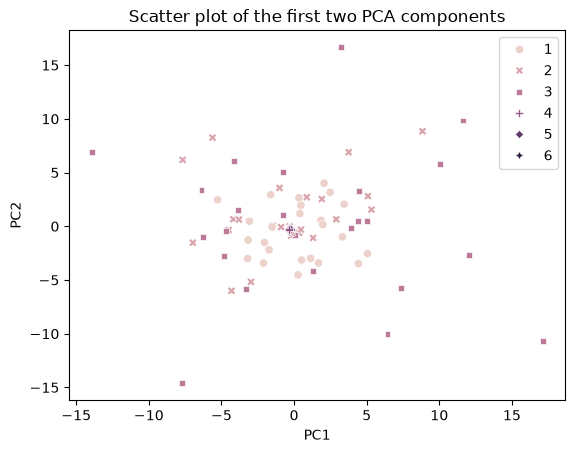

In [17]:
sns.scatterplot(x='PC1', y='PC2', style=y_train_val, data=pca_xtrain_df, hue = y_train_val) # Plotting the scatter plot of the first two PCA components
plt.title("Scatter plot of the first two PCA components")
plt.show()

In [18]:
fig = px.scatter(pca_xtrain_df, x='PC1', y='PC2', color=y_train_val, title="Interactive scatter plot of the first two PCA components") # Plotting the Interactive scatter plot of the first two PCA components in Plotly
fig.show()

<style>p {text-align: left; font-family: "Times New Roman";}</style>
<p>It can be observed from the above plots that the PCA has not captured the distribution well and the datapoints still appear to be too much scattered. This can be observed by zooming into the plotly plot. the Decision tree classifier would not be able to form complicated decision boundaries if its height is restricted, and hence, this dataset may not be suitable for classification by Decision Tree. In the next part, TSFEL is used.</p>

In [19]:
# Retrieves a pre-defined feature configuration file to extract all available features
cfg = tsfel.get_features_by_domain()
features_xTrainVal_lis = [] # Creating a list for storing the features for each sample in the train and validation parts of the dataset
for i in range(len(X_train_val)): # Looping over the train and validation parts of the dataset
    features_xTrainVal_lis.append(np.array(tsfel.time_series_features_extractor(cfg, X_train_val[i], fs=50, verbose=0))) # Extracting the features for each sample in the train and validation parts of the dataset and appending it to the list


features_xTrainVal_arr = np.array(features_xTrainVal_lis).reshape(144, -1) # Converting the list to an array and reshaping it

In [20]:
features_xTest_lis = [] # Creating a list for storing the features for each sample in the test set
for i in range(len(a_net_test_arr)): # Looping over the test set
    features_xTest_lis.append(np.array(tsfel.time_series_features_extractor(cfg, a_net_test_arr[i], fs=50, verbose=0))) # Extracting the features for each sample in the test set and appending it to the list

features_xTest_arr = np.array(features_xTest_lis).reshape(36, -1) # Converting the list to an array and reshaping it

In [21]:
features_xTrainVal_df = pd.DataFrame(features_xTrainVal_arr) # Creating a dataframe for the features for each sample in the train and validation parts of the dataset
pca_features = PCA(n_components=2) # Creating a PCA object
pca_features_xTrainVal_df = pca_features.fit_transform(features_xTrainVal_df) # Fitting the PCA object on the train and validation parts of the dataset
pca_features_xTrainVal_df = pd.DataFrame(data = pca_features_xTrainVal_df, columns = ['PC1', 'PC2']) # Creating a dataframe for the PCA components with PCA1 and PCA2 as the column names

pca_features_xTrainVal_df

,PC1,PC2
0,60364.539241,62.602475
1,56461.869536,21.104842
2,-53312.033134,-71.646722
3,-64464.302035,-13.847400
4,61276.376276,31.048674
...,...,...
139,62461.781184,-36.960135
140,61920.820730,36.511838
141,59797.379991,69.762157
142,-164906.572661,277.269062


In [22]:
pca_features_xTest_df = pca_features.transform(features_xTest_arr) # Transforming the test set using the PCA object
pca_features_xTest_df = pd.DataFrame(data = pca_features_xTest_df, columns = ['PC1', 'PC2']) # Creating a dataframe for the PCA components with PCA1 and PCA2 as the column names

pca_features_xTest_df

,PC1,PC2
0,-126705.577176,-89.342781
1,-114419.638186,40.965280
2,60358.038837,-44.190564
3,-33406.429391,-124.498886
4,63974.654961,20.254931
5,56896.038380,23.228467
6,64417.330045,-0.776400
7,-38291.891269,-163.383222
8,-26658.919774,-127.490410
9,-77342.584618,-80.778052


In [23]:
import pickle # Importing the pickle library for pickling the PCA object

filename = 'Final Model/pca_features.sav' # Path for the PCA object
pickle.dump(pca_features, open(filename, 'wb')) # Pickling/Saving the PCA object

Text(0, 0.5, 'PC2')

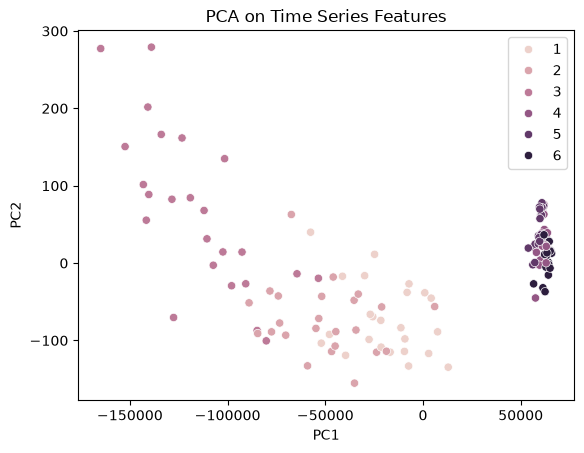

In [24]:
sns.scatterplot(x='PC1', y='PC2', hue=y_train_val, data=pca_features_xTrainVal_df) # Plotting the scatter plot of the first two PCA components of the features for each sample in the train and validation parts of the dataset
plt.title('PCA on Time Series Features')
plt.xlabel('PC1')
plt.ylabel('PC2')

In [25]:
fig = px.scatter(pca_features_xTrainVal_df, x='PC1', y='PC2', color=y_train_val, title="Interactive scatter plot of the first two PCA components of the features for each sample in the train and validation parts of the dataset") # Plotting the Interactive scatter plot of the first two PCA components of the features for each sample in the train and validation parts of the dataset in Plotly
fig.show()

Text(0, 0.5, 'PC2')

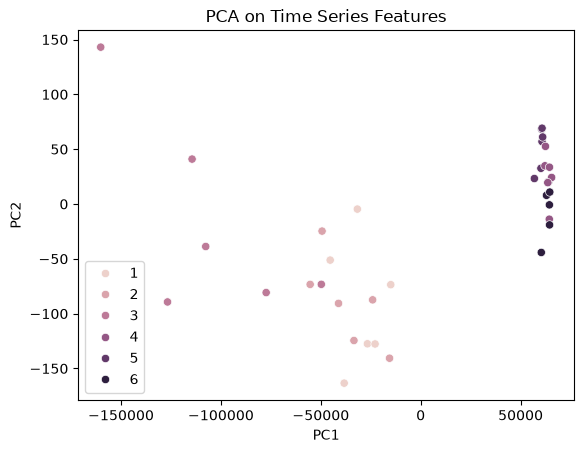

In [26]:
sns.scatterplot(x='PC1', y='PC2', hue=y_test, data=pca_features_xTest_df)
plt.title('PCA on Time Series Features')
plt.xlabel('PC1')
plt.ylabel('PC2')

In [27]:
fig = px.scatter(pca_features_xTest_df, x='PC1', y='PC2', color=y_test, title="Interactive scatter plot of the first two PCA components of the features for each sample in the test set") # Plotting the Interactive scatter plot of the first two PCA components of the features for each sample in the test set in Plotly
fig.show()

<style>p {text-align: left; font-family: "Times New Roman";}</style>
<p> In the scatter plots from plotly, the main thing that can be seen is that the classes are much segregated in the scatter plot after the Time series feature extraction compared to before it. So, it is a better option to perform the Time series feature extraction and then perform PCA as the activities are distinctly visible in their respective clusters for which it is relatively easier to form decision boundaries</p>

## 6. Decision Tree on the TSFEL Features

<style>p {text-align: left; font-family: "Times New Roman";}</style>
<p>Using the features obtained from TSFEL (after PCA) to train a Decision Tree and reporting the accuracy and confusion matrix using the test set, to see whether featurizing works better than using the raw data. Decision Trees with varying depths (2-8) are trained, and the accuracies are plotted against the accuracies obtained using the raw data in Section 4.</p>

Text(0.5, 1.0, 'The Mean Cross Validation Accuracy against the height of the tree')

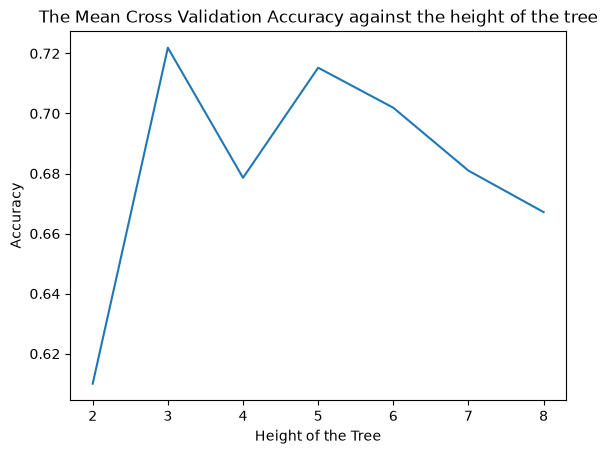

In [28]:
dict_heightVSaccuracy1 = {} # Creating a dictionary for storing the accuracy of the model for each max depth
for i in range(2,9): # Looping over the max depth
    dtree = DecisionTreeClassifier(max_depth=i, random_state=42) # Creating a decision tree classifier of max depth = i
    arr = cross_val_score(dtree, pca_features_xTrainVal_df, y_train_val, cv=10) # Calculating the cross validation score
    dict_heightVSaccuracy1[i] = arr.mean() # Storing the accuracy of the model for each max depth
plt.plot(dict_heightVSaccuracy1.keys(), dict_heightVSaccuracy1.values()) # Plotting the accuracy of the model for each max depth
plt.xlabel("Height of the Tree")
plt.ylabel("Accuracy")
plt.title("The Mean Cross Validation Accuracy against the height of the tree")

Accuracy Score for max depth =  2 is 0.5555555555555556
Confusion Matrix for max depth =  2


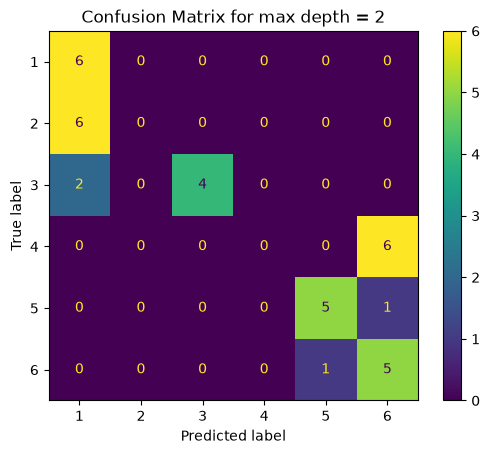

-----------------------------------------------------------
Accuracy Score for max depth =  3 is 0.6944444444444444
Confusion Matrix for max depth =  3


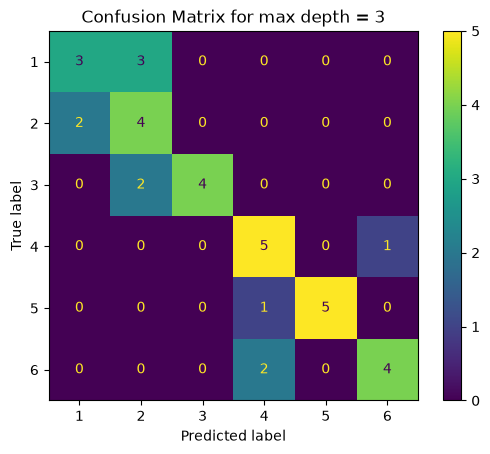

-----------------------------------------------------------
Accuracy Score for max depth =  4 is 0.6944444444444444
Confusion Matrix for max depth =  4


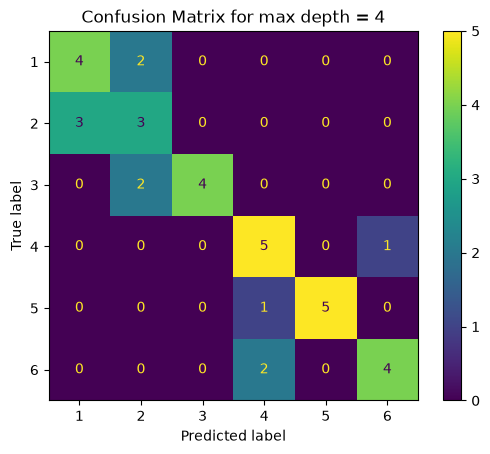

-----------------------------------------------------------
Accuracy Score for max depth =  5 is 0.6388888888888888
Confusion Matrix for max depth =  5


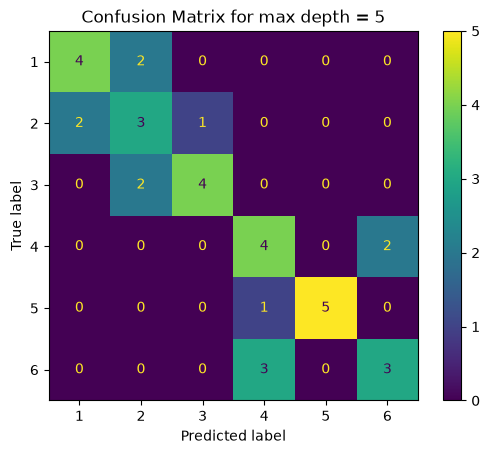

-----------------------------------------------------------
Accuracy Score for max depth =  6 is 0.5277777777777778
Confusion Matrix for max depth =  6


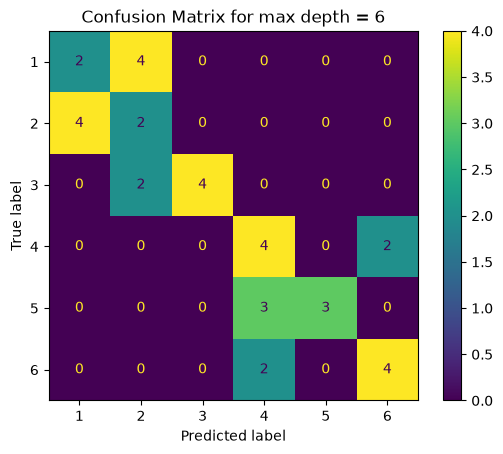

-----------------------------------------------------------
Accuracy Score for max depth =  7 is 0.4444444444444444
Confusion Matrix for max depth =  7


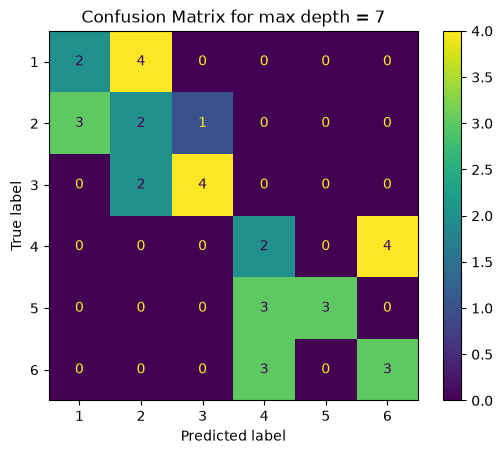

-----------------------------------------------------------
Accuracy Score for max depth =  8 is 0.5555555555555556
Confusion Matrix for max depth =  8


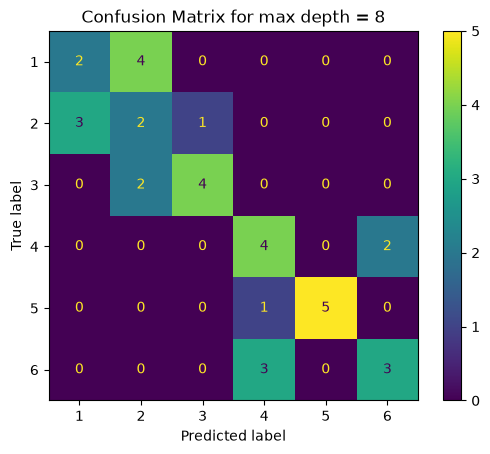

-----------------------------------------------------------


In [29]:
dict_heightVSaccuracy2 = {} # Creating a dictionary for storing the accuracy of the model for each max depth
for i in range(2, 9): # Looping over the max depth
    dtree = DecisionTreeClassifier(max_depth=i, random_state=42) # Creating a decision tree classifier of max depth = i
    dtree.fit(pca_features_xTrainVal_df, y_train_val) # Fitting the decision tree classifier on the train and validation parts of the dataset
    ypred = dtree.predict(pca_features_xTest_df) # Predicting the labels for the test set
    print("Accuracy Score for max depth = ", i, "is", accuracy_score(y_test, ypred)) # Printing the accuracy of the model on the test set
    print("Confusion Matrix for max depth = ", i) # Printing the confusion matrix
    dict_heightVSaccuracy2[i] = accuracy_score(y_test, ypred) # Storing the accuracy of the model for each max depth
    cm = confusion_matrix(y_test, ypred) # Calculating the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dtree.classes_) # Creating a confusion matrix display
    disp.plot() # Plotting the confusion matrix
    plt.title("Confusion Matrix for max depth = "+str(i)) 
    plt.show()
    print("-----------------------------------------------------------")

Text(0.5, 1.0, 'Accuracy vs Height plot for PCA on Time Series features')

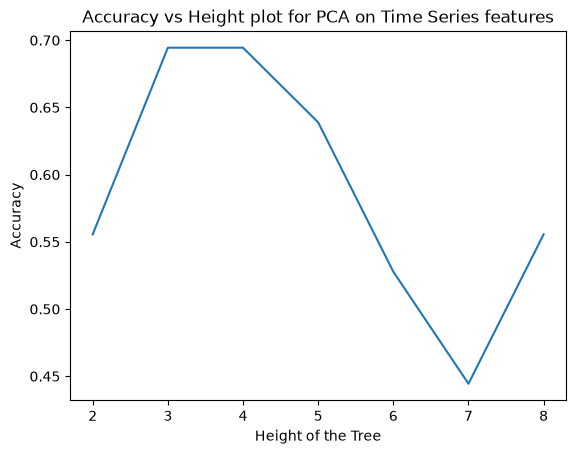

In [30]:
acc_axis = dict_heightVSaccuracy2.values() # Creating an array for storing the accuracy of the model for each max depth for PCA on Time Series Features
height_axis = dict_heightVSaccuracy.keys() # Creating an array for storing the max depth

plt.figure()
plt.plot(height_axis, acc_axis)
plt.xlabel("Height of the Tree")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Height plot for PCA on Time Series features")

Text(0.5, 1.0, 'Accuracy vs Height of Tree')

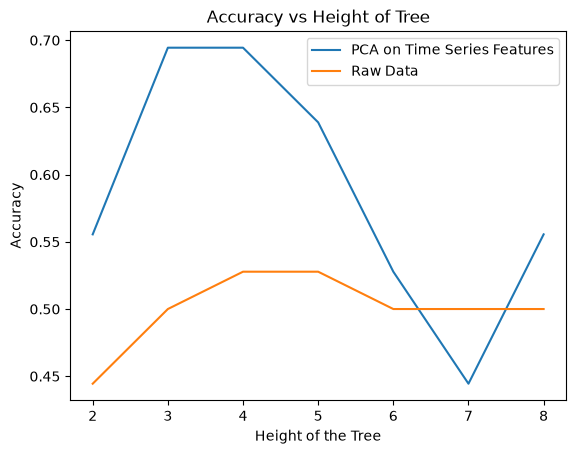

In [31]:
acc_features_axis = dict_heightVSaccuracy2.values() # Creating an array for storing the accuracy of the model for each max depth for PCA on Time Series Features
acc_noTSFEL_axis = dict_heightVSaccuracy.values() # Creating an array for storing the accuracy of the model for each max depth no PCA and no TSFEL (raw data)
height_axis = dict_heightVSaccuracy.keys() # Creating an array for storing the max depth

plt.figure()
plt.plot(height_axis, acc_features_axis, label="PCA on Time Series Features") # Plotting the accuracy of the model for each max depth for PCA on Time Series Features
plt.plot(height_axis, acc_noTSFEL_axis, label="Raw Data") # Plotting the accuracy of the model for each max depth no PCA and no TSFEL (raw data)
plt.xlabel("Height of the Tree")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy vs Height of Tree")

In [32]:
final_dtree = DecisionTreeClassifier(max_depth=4, random_state=42) # Creating a decision tree classifier of max depth = 4 (Final Model)
final_dtree.fit(pca_features_xTrainVal_df, y_train_val) # Fitting the decision tree classifier on the train and validation parts of the dataset
ypred = final_dtree.predict(pca_features_xTest_df) # Predicting the labels for the test set
print("The Accuracy Score of the Final Model is", accuracy_score(y_test, ypred)*100, "%") # Printing the accuracy of the model on the test set

The Accuracy Score of the Final Model is 69.44444444444444 %


In [33]:
filename = 'Final Model/final_tree.sav' # Path for the Final Model
pickle.dump(final_dtree, open(filename, 'wb')) # Pickling/Saving the Final Model

loaded_model = pickle.load(open(filename, 'rb')) # Loading the Final Model

Text(0.5, 1.0, 'Final Model')

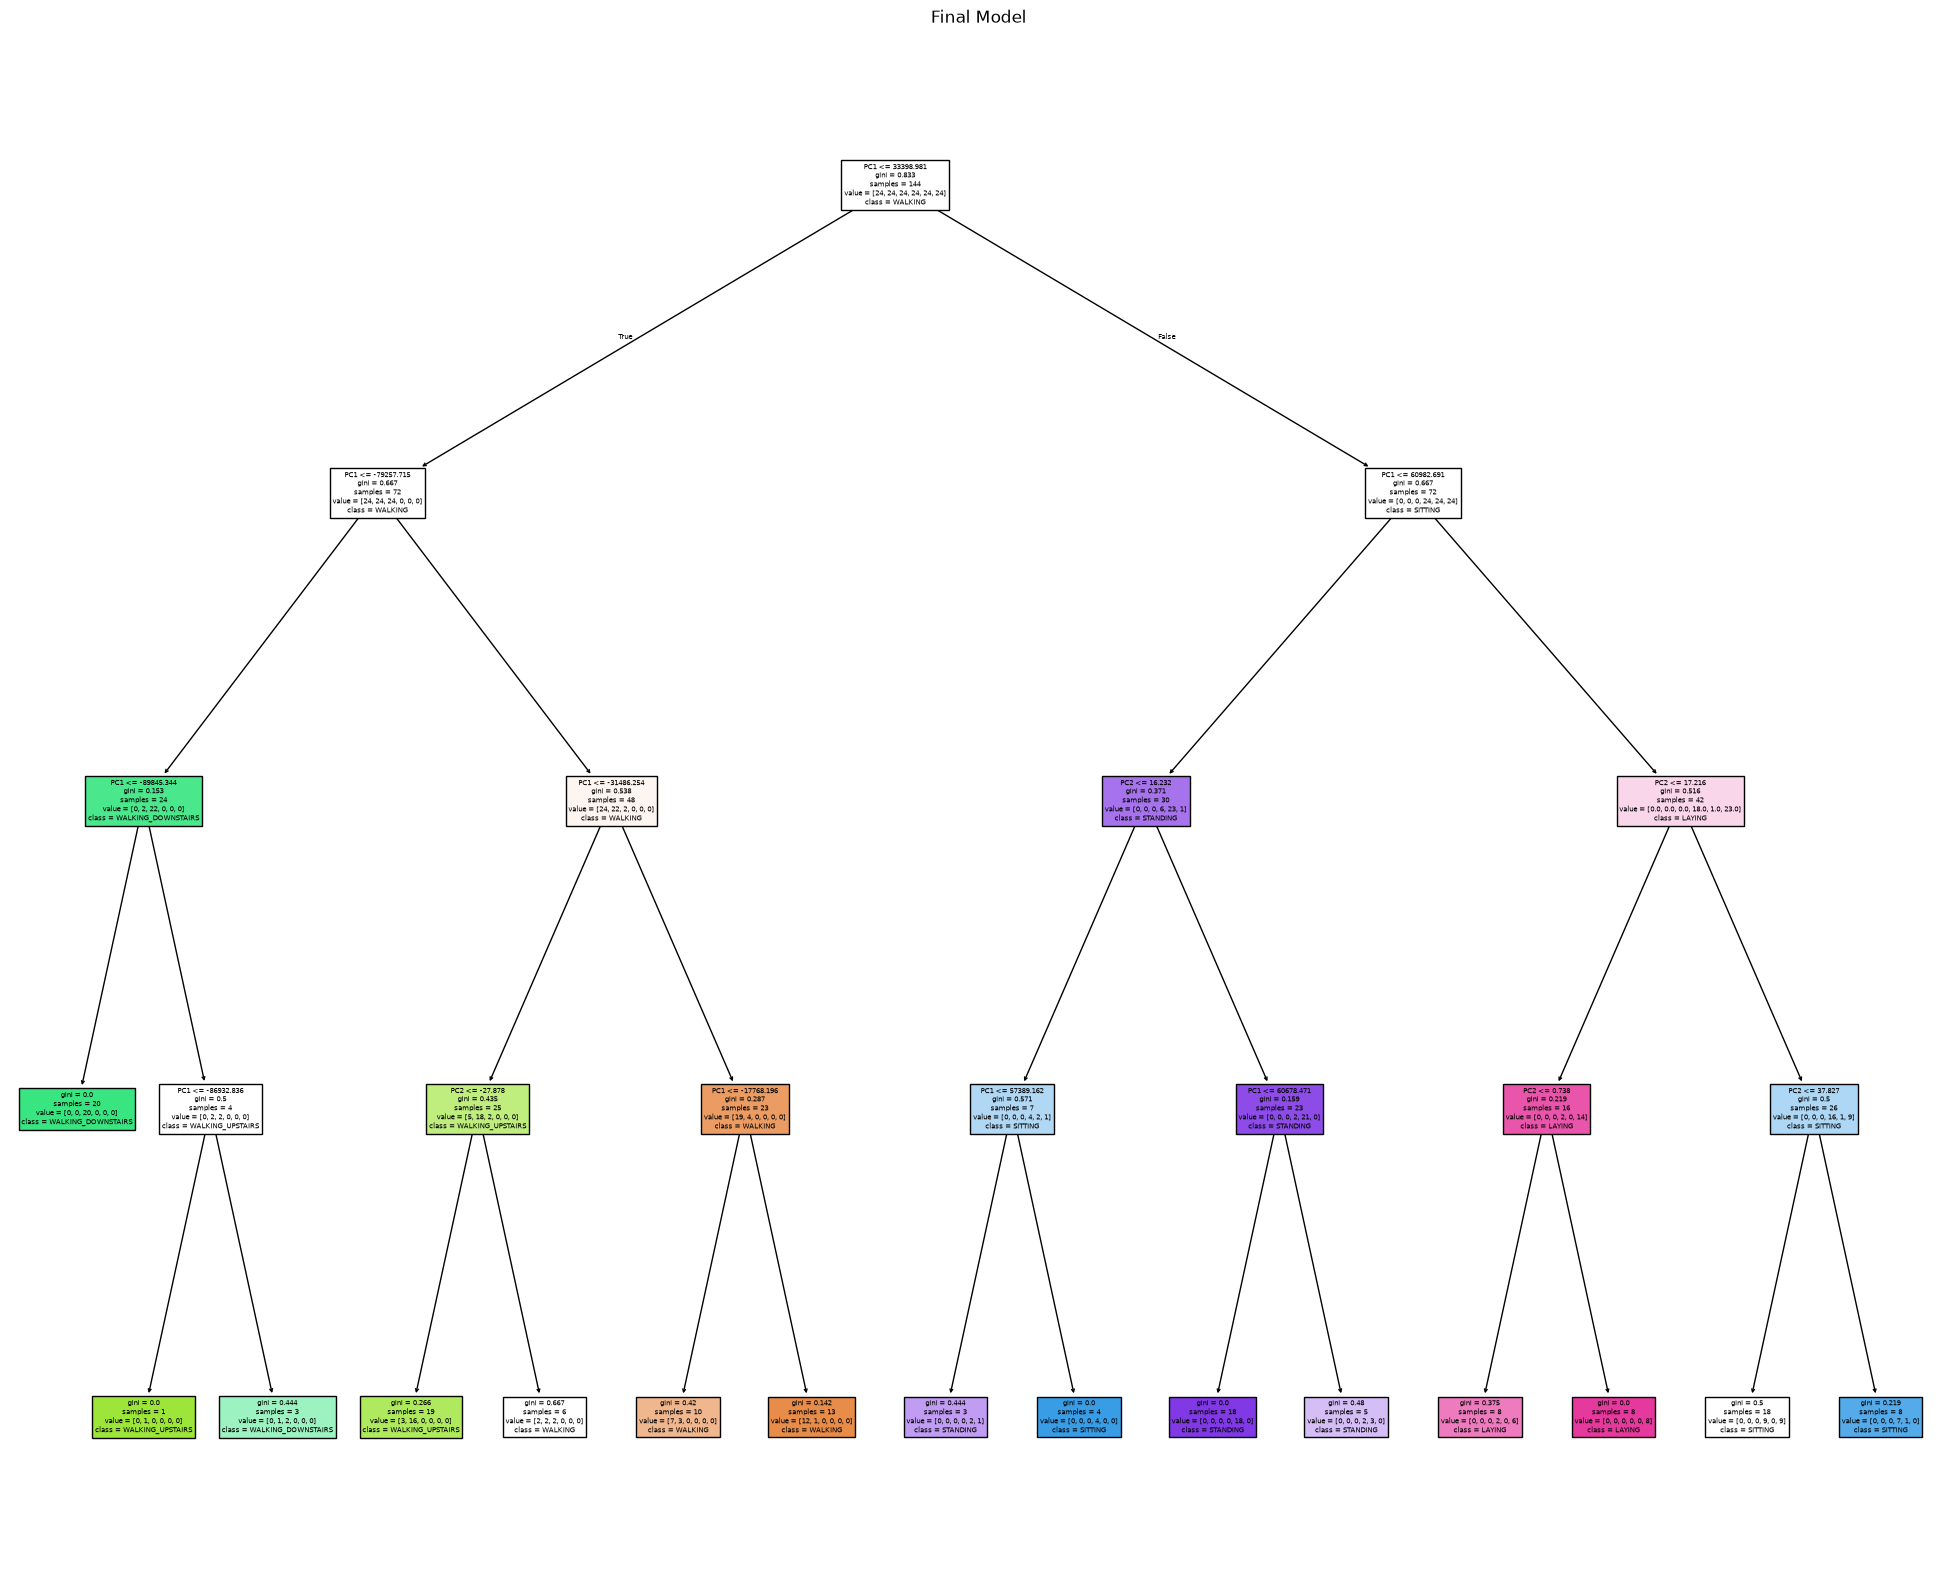

In [34]:
fig = plt.figure(figsize=(25,20))
_ = tree.plot_tree(loaded_model,
                   feature_names=["PC1", "PC2"],  
                   class_names = ["WALKING","WALKING_UPSTAIRS","WALKING_DOWNSTAIRS","SITTING","STANDING","LAYING"] ,
                   filled=True) # Plotting the Final Model
plt.title("Final Model")

<style>p {text-align: left; font-family: "Times New Roman";}</style>
<p> It can be observed that the accuracy of the tree on the test data is the maximum at the heights of 3 and 4. So, the final tree is of height 4. It can also be observed that the working of the model on the PCA of the timeseries of the dataset is much better than that on unprocessed dataset. The model has also been saved for later use.</p>

## 7. Activities where the Model Performance is Bad

<style>p {text-align: left; font-family: "Times New Roman";}</style>
<p>Looking at the activities where the performance of the final model is bad, and why.</p>

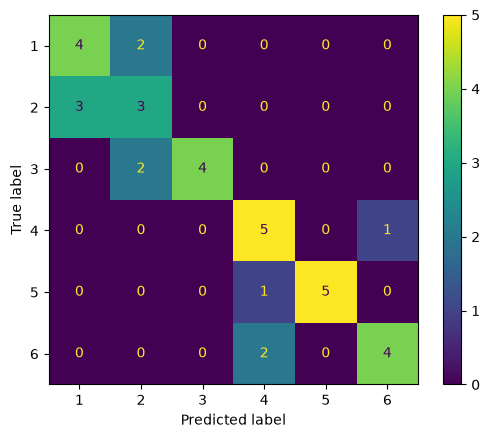

In [35]:
cm = confusion_matrix(y_test, ypred) # Calculating the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dtree.classes_) # Creating a confusion matrix display
disp.plot()
plt.show()

In [36]:
print(classification_report(y_test, ypred)) # Printing the classification report

              precision    recall  f1-score   support

           1       0.57      0.67      0.62         6
           2       0.43      0.50      0.46         6
           3       1.00      0.67      0.80         6
           4       0.62      0.83      0.71         6
           5       1.00      0.83      0.91         6
           6       0.80      0.67      0.73         6

    accuracy                           0.69        36
   macro avg       0.74      0.69      0.70        36
weighted avg       0.74      0.69      0.70        36



<style>p {text-align: left; font-family: "Times New Roman";}</style>
<p>The worst activity is the one with class 2 that is Walking Upstairs. The Reason for this is that the model is frequently confusing the Walking Upstairs activity with similar dynamic activities such as walking, and walking downwards.</p>
